In [10]:
# ===== CODE BLOCK 1: Install/Import Libraries and Load Dataset =====

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load dataset (Kaggle input path — adjust if dataset folder name differs)
DATA_PATH = '/kaggle/input/datasets/heeeeyyy/adult-census-income/adult.csv'
df = pd.read_csv('/kaggle/input/datasets/heeeeyyy/adult-census-income/adult.csv')

print("Dataset loaded successfully!")
print(f"File path: {'/kaggle/input/datasets/heeeeyyy/adult-census-income/adult.csv'}")

Dataset loaded successfully!
File path: /kaggle/input/datasets/heeeeyyy/adult-census-income/adult.csv


In [11]:
# ===== CODE BLOCK 2: EDA - Shape, Class Distribution, First 5 Rows =====

print("=" * 50)
print("DATASET SHAPE")
print("=" * 50)
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n" + "=" * 50)
print("CLASS DISTRIBUTION (Target: income)")
print("=" * 50)
print(df['income'].value_counts())
print("\nClass distribution (%):")
print(df['income'].value_counts(normalize=True) * 100)

print("\n" + "=" * 50)
print("FIRST 5 ROWS")
print("=" * 50)
print(df.head())

print("\n" + "=" * 50)
print("COLUMN INFO")
print("=" * 50)
print(df.info())

DATASET SHAPE
Rows: 32561, Columns: 15

CLASS DISTRIBUTION (Target: income)
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Class distribution (%):
income
<=50K    75.919044
>50K     24.080956
Name: proportion, dtype: float64

FIRST 5 ROWS
   age workclass  fnlwgt     education  education.num marital.status  \
0   90         ?   77053       HS-grad              9        Widowed   
1   82   Private  132870       HS-grad              9        Widowed   
2   66         ?  186061  Some-college             10        Widowed   
3   54   Private  140359       7th-8th              4       Divorced   
4   41   Private  264663  Some-college             10      Separated   

          occupation   relationship   race     sex  capital.gain  \
0                  ?  Not-in-family  White  Female             0   
1    Exec-managerial  Not-in-family  White  Female             0   
2                  ?      Unmarried  Black  Female             0   
3  Machine-op-inspct      Unmarried  Wh

In [12]:
# ===== CODE BLOCK 3: Data Preprocessing =====

# Make a working copy
data = df.copy()

# The Adult dataset uses '?' as missing value marker instead of NaN
data.replace('?', np.nan, inplace=True)

# Check missing values
print("Missing values per column:\n", data.isnull().sum()[data.isnull().sum() > 0])

# Handle missing values: drop rows with any missing value (simple strategy)
data.dropna(inplace=True)
print(f"\nShape after dropping missing values: {data.shape}")

# Encode target column (binary: <=50K -> 0, >50K -> 1)
target_encoder = LabelEncoder()
data['income'] = target_encoder.fit_transform(data['income'])
print(f"\nTarget classes mapped: {list(target_encoder.classes_)} -> {list(range(len(target_encoder.classes_)))}")

# Encode categorical feature columns using LabelEncoder
categorical_cols = data.select_dtypes(include='object').columns
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])

print(f"\nEncoded categorical columns: {list(categorical_cols)}")

# Split into features (X) and target (y)
X = data.drop('income', axis=1)
y = data['income']

print(f"\nX shape: {X.shape}, y shape: {y.shape}")

# ---------------------------------------------------------------
# NOTE — Same dataset for other learning strategies:
#
# UNSUPERVISED LEARNING:
#   - Drop 'income' entirely, use only X.
#   - Apply KMeans(n_clusters=2) or DBSCAN to see if the algorithm
#     naturally discovers the same 2 groups without seeing labels.
#   - Evaluate with metrics like Silhouette Score or Adjusted Rand
#     Index (comparing clusters to the true 'income' labels only
#     for external validation, not for training).
#
# SEMI-SUPERVISED LEARNING:
#   - Keep the same X, y, but artificially mask most labels, e.g.:
#       y_semi = y.copy()
#       mask = np.random.rand(len(y_semi)) < 0.90   # hide 90% of labels
#       y_semi[mask] = -1   # -1 = "unlabeled" marker
#   - Use sklearn.semi_supervised.LabelPropagation, LabelSpreading,
#     or SelfTrainingClassifier(RandomForestClassifier()) to train
#     on the small labeled subset + large unlabeled subset.
# ---------------------------------------------------------------

Missing values per column:
 workclass         1836
occupation        1843
native.country     583
dtype: int64

Shape after dropping missing values: (30162, 15)

Target classes mapped: ['<=50K', '>50K'] -> [0, 1]

Encoded categorical columns: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']

X shape: (30162, 14), y shape: (30162,)


In [13]:
# ===== CODE BLOCK 4: Train-Test Split 80:20 =====

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y  # preserve class ratio in both splits
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

print("\nTrain class distribution:\n", y_train.value_counts(normalize=True))
print("\nTest class distribution:\n", y_test.value_counts(normalize=True))

X_train shape: (24129, 14)
X_test shape:  (6033, 14)
y_train shape: (24129,)
y_test shape:  (6033,)

Train class distribution:
 income
0    0.751088
1    0.248912
Name: proportion, dtype: float64

Test class distribution:
 income
0    0.751036
1    0.248964
Name: proportion, dtype: float64


In [14]:
# ===== CODE BLOCK 5: Train RandomForestClassifier with Default Parameters =====

# No hyperparameter tuning — using scikit-learn defaults
# Only random_state is set for reproducibility (does not affect "default" behavior)
model = RandomForestClassifier(random_state=42)

model.fit(X_train, y_train)

print("Model training complete!")
print(f"Model: {model}")
print(f"Number of trees (n_estimators): {model.n_estimators}")

Model training complete!
Model: RandomForestClassifier(random_state=42)
Number of trees (n_estimators): 100


In [15]:
# ===== CODE BLOCK 6: Predictions on Test Set =====

# Class predictions
y_pred = model.predict(X_test)

# Predicted probabilities (needed for AUROC)
y_pred_proba = model.predict_proba(X_test)[:, 1]  # probability of class "1" (>50K)

print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_test.values[:10])
print("\nFirst 10 predicted probabilities (class=1):", np.round(y_pred_proba[:10], 3))

First 10 predictions: [0 0 1 0 0 1 0 0 0 1]
First 10 actual values: [0 0 1 0 0 1 1 0 0 1]

First 10 predicted probabilities (class=1): [0.12 0.35 0.91 0.01 0.01 0.65 0.07 0.   0.   0.84]


In [16]:
# ===== CODE BLOCK 7: Model Evaluation =====

# EM (Exact Match) — same as Accuracy for single-label classification
EM = accuracy_score(y_test, y_pred)

# ACC (Accuracy) — same metric, listed separately as required
ACC = accuracy_score(y_test, y_pred)

# MCC (Matthews Correlation Coefficient)
MCC = matthews_corrcoef(y_test, y_pred)

# AUROC (Area Under ROC Curve) — needs predicted probabilities
AUROC = roc_auc_score(y_test, y_pred_proba)

print("=" * 40)
print("MODEL EVALUATION METRICS")
print("=" * 40)
print(f"EM (Exact Match)    : {EM:.4f}")
print(f"ACC (Accuracy)       : {ACC:.4f}")
print(f"MCC                  : {MCC:.4f}")
print(f"AUROC                : {AUROC:.4f}")

MODEL EVALUATION METRICS
EM (Exact Match)    : 0.8636
ACC (Accuracy)       : 0.8636
MCC                  : 0.6178
AUROC                : 0.9136


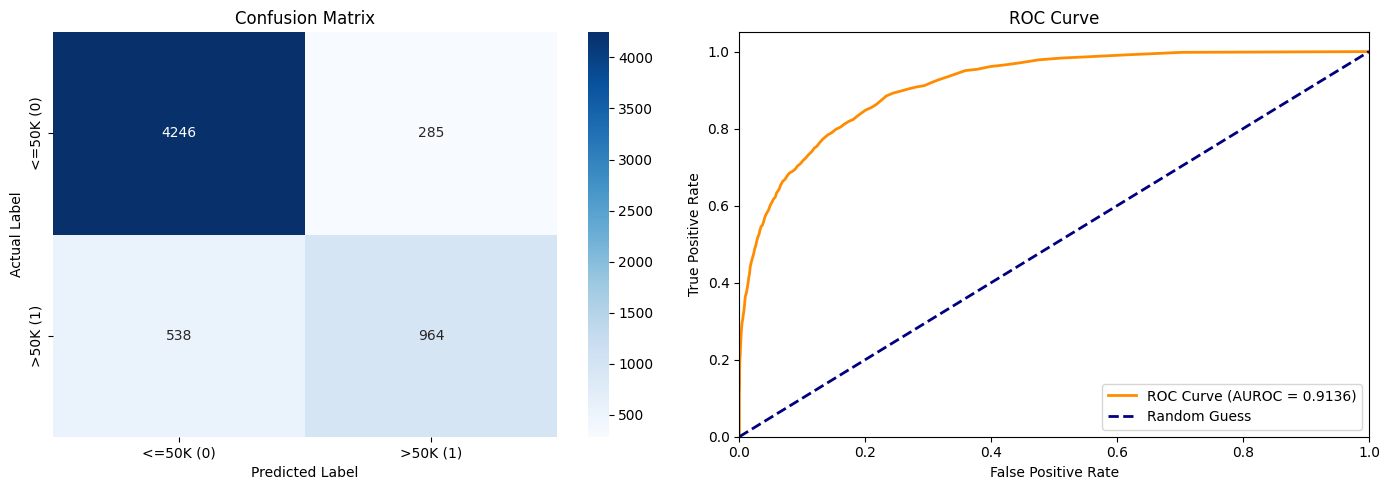


FINAL SUMMARY TABLE
          Metric  Score
EM (Exact Match) 0.8636
  ACC (Accuracy) 0.8636
             MCC 0.6178
           AUROC 0.9136


In [17]:
# ===== CODE BLOCK 8: Confusion Matrix and ROC Curve Plot =====

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['<=50K (0)', '>50K (1)'],
            yticklabels=['<=50K (0)', '>50K (1)'],
            ax=axes[0])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# --- ROC Curve ---
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
axes[1].plot(fpr, tpr, color='darkorange', lw=2,
             label=f'ROC Curve (AUROC = {AUROC:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# ===== FINAL SUMMARY TABLE =====
summary_df = pd.DataFrame({
    'Metric': ['EM (Exact Match)', 'ACC (Accuracy)', 'MCC', 'AUROC'],
    'Score': [round(EM, 4), round(ACC, 4), round(MCC, 4), round(AUROC, 4)]
})

print("\n" + "=" * 40)
print("FINAL SUMMARY TABLE")
print("=" * 40)
print(summary_df.to_string(index=False))

In [19]:
# ===== CODE BLOCK 9: Strip Labels + Feature Scaling (Unsupervised Prep) =====
# TRUE unsupervised learning must never expose the target column to the
# algorithm. To make this explicit and impossible to mix up accidentally,
# we physically drop 'income' from the dataframe here and store the
# original labels under a clearly-separate name that is ONLY touched
# after clustering is complete (for validation, not training).

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Step 1: Build a features-only dataframe with NO label column at all
X_unsupervised = data.drop(columns=['income']).copy()

# Step 2: Set the true labels aside under an explicit "validation only" name.
# This variable is NEVER passed into .fit() or .fit_predict() below —
# it only appears once, later, purely to score the result afterward.
y_true_for_validation_only = data['income'].copy()

print("Confirming label removal:")
print(f"Columns available to the clustering algorithm: {list(X_unsupervised.columns)}")
print(f"'income' present in clustering features? {'income' in X_unsupervised.columns}")

# Step 3: Scale features — clustering is distance-based, so scaling
# prevents large-magnitude columns (e.g. 'fnlwgt') from dominating
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_unsupervised)

print(f"\nX_unsupervised shape: {X_unsupervised.shape}")
print(f"X_scaled shape:       {X_scaled.shape}")

Confirming label removal:
Columns available to the clustering algorithm: ['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country']
'income' present in clustering features? False

X_unsupervised shape: (30162, 14)
X_scaled shape:       (30162, 14)


In [20]:
# ===== CODE BLOCK 10: Train KMeans with 2 Clusters (No Labels Used) =====
# Only X_scaled is passed in. There is no y argument anywhere in this
# block — sklearn's KMeans.fit_predict() doesn't even accept one,
# which is itself proof this step is 100% unsupervised.

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)   # <-- features only, no labels involved

print("KMeans training complete (trained with zero label information).")
print(f"Cluster centers shape: {kmeans.cluster_centers_.shape}")
print(f"\nCluster 0 count: {np.sum(cluster_labels == 0)}")
print(f"Cluster 1 count: {np.sum(cluster_labels == 1)}")

KMeans training complete (trained with zero label information).
Cluster centers shape: (2, 14)

Cluster 0 count: 17593
Cluster 1 count: 12569


UNSUPERVISED LEARNING - CLUSTERING METRICS
Silhouette Score (internal, label-free) : 0.1363
Adjusted Rand Index (external validation): 0.0298
(ARI compares clusters to true labels AFTER the fact only)


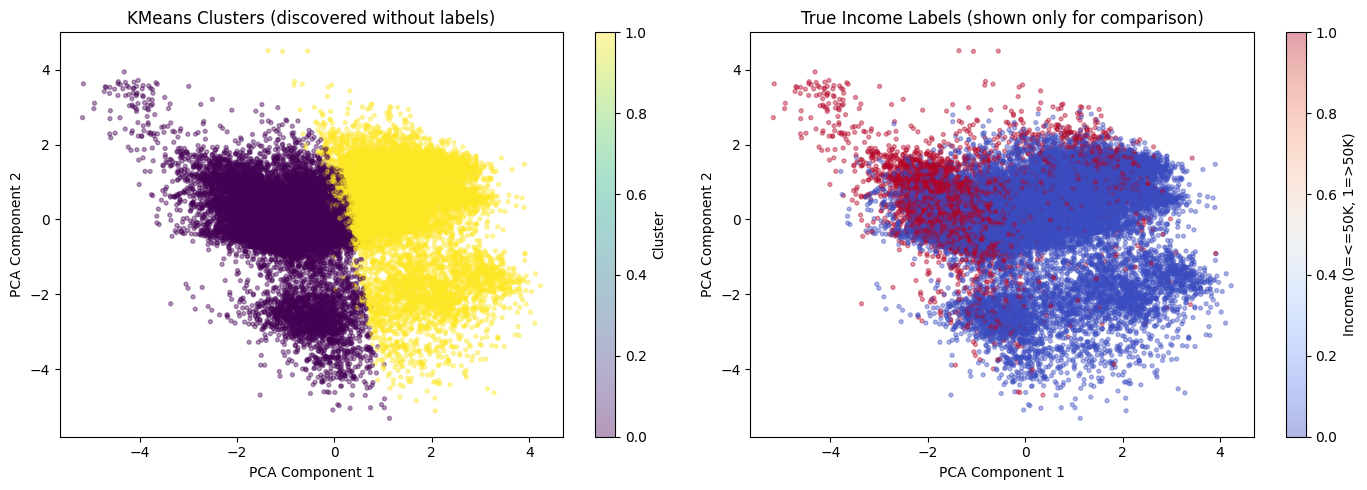

In [21]:
# ===== CODE BLOCK 11: Evaluate Clustering Quality =====
#
# Two very different kinds of metrics below:
#
#  (A) Silhouette Score — an INTERNAL metric. Needs ONLY X_scaled and
#      cluster_labels. Proves cluster quality can be measured without
#      ever looking at y_true_for_validation_only.
#
#  (B) Adjusted Rand Index (ARI) — an EXTERNAL validation metric. This
#      is the ONLY line in this entire unsupervised section that touches
#      y_true_for_validation_only, and it is used strictly to check,
#      after training is finished, whether the discovered clusters
#      happen to resemble the real income groups. It plays no role in
#      how the clusters were formed.

# (A) Internal metric — no labels needed
sil_score = silhouette_score(X_scaled, cluster_labels)

# (B) External validation — labels used ONLY here, ONLY to score
ari_score = adjusted_rand_score(y_true_for_validation_only, cluster_labels)

print("=" * 55)
print("UNSUPERVISED LEARNING - CLUSTERING METRICS")
print("=" * 55)
print(f"Silhouette Score (internal, label-free) : {sil_score:.4f}")
print(f"Adjusted Rand Index (external validation): {ari_score:.4f}")
print("(ARI compares clusters to true labels AFTER the fact only)")

# Visualize clusters in 2D using PCA for dimensionality reduction
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels,
                             cmap='viridis', alpha=0.4, s=8)
axes[0].set_title('KMeans Clusters (discovered without labels)')
axes[0].set_xlabel('PCA Component 1')
axes[0].set_ylabel('PCA Component 2')
plt.colorbar(scatter1, ax=axes[0], label='Cluster')

scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true_for_validation_only,
                             cmap='coolwarm', alpha=0.4, s=8)
axes[1].set_title('True Income Labels (shown only for comparison)')
axes[1].set_xlabel('PCA Component 1')
axes[1].set_ylabel('PCA Component 2')
plt.colorbar(scatter2, ax=axes[1], label='Income (0=<=50K, 1=>50K)')

plt.tight_layout()
plt.show()

In [22]:
# ===== CODE BLOCK 12: Simulate a Semi-Supervised Scenario =====
# We artificially "hide" most training labels to simulate a real-world
# scenario where labeling data is expensive and only a small fraction
# is labeled. sklearn's convention: unlabeled samples get y = -1

from sklearn.semi_supervised import SelfTrainingClassifier

np.random.seed(42)

# Start from the SAME train split used in the supervised task (X_train, y_train)
y_train_semi = y_train.copy().to_numpy()

# Hide 90% of labels — only 10% remain "labeled"
mask = np.random.rand(len(y_train_semi)) < 0.90
y_train_semi[mask] = -1  # -1 marks "unlabeled" in sklearn's semi-supervised API

n_labeled = np.sum(y_train_semi != -1)
n_unlabeled = np.sum(y_train_semi == -1)

print(f"Total training samples : {len(y_train_semi)}")
print(f"Labeled samples (10%)  : {n_labeled}")
print(f"Unlabeled samples (90%): {n_unlabeled}")
print(f"\nLabeled class distribution:\n{pd.Series(y_train_semi[y_train_semi != -1]).value_counts()}")

Total training samples : 24129
Labeled samples (10%)  : 2434
Unlabeled samples (90%): 21695

Labeled class distribution:
0    1813
1     621
Name: count, dtype: int64


In [23]:
# ===== CODE BLOCK 13: Train SelfTrainingClassifier =====
# SelfTrainingClassifier wraps our SAME RandomForestClassifier (default params)
# as the base estimator. It trains on the small labeled subset, predicts
# pseudo-labels for the unlabeled subset with high confidence, adds those
# to the training set, and iterates.

base_rf = RandomForestClassifier(random_state=42)
self_training_model = SelfTrainingClassifier(base_rf)

self_training_model.fit(X_train, y_train_semi)

print("Semi-supervised training complete!")
print(f"Number of self-training iterations: {self_training_model.n_iter_}")
print(f"Final labeled samples used: {np.sum(self_training_model.labeled_iter_ != -1)}")

Semi-supervised training complete!
Number of self-training iterations: 10
Final labeled samples used: 23592


In [24]:
# ===== CODE BLOCK 14: Semi-Supervised Predictions and Evaluation =====
# Evaluate on the SAME held-out X_test/y_test used by the supervised model,
# using the SAME 4 metrics, for a fair side-by-side comparison

y_pred_semi = self_training_model.predict(X_test)
y_pred_proba_semi = self_training_model.predict_proba(X_test)[:, 1]

EM_semi = accuracy_score(y_test, y_pred_semi)
ACC_semi = accuracy_score(y_test, y_pred_semi)
MCC_semi = matthews_corrcoef(y_test, y_pred_semi)
AUROC_semi = roc_auc_score(y_test, y_pred_proba_semi)

print("=" * 40)
print("SEMI-SUPERVISED LEARNING - EVALUATION METRICS")
print("=" * 40)
print(f"(Trained using only 10% labeled data + 90% unlabeled data)")
print(f"EM (Exact Match)    : {EM_semi:.4f}")
print(f"ACC (Accuracy)       : {ACC_semi:.4f}")
print(f"MCC                  : {MCC_semi:.4f}")
print(f"AUROC                : {AUROC_semi:.4f}")

SEMI-SUPERVISED LEARNING - EVALUATION METRICS
(Trained using only 10% labeled data + 90% unlabeled data)
EM (Exact Match)    : 0.8478
ACC (Accuracy)       : 0.8478
MCC                  : 0.5674
AUROC                : 0.8671


In [25]:
# ===== CODE BLOCK 15: Final Comparison Summary =====

comparison_df = pd.DataFrame({
    'Metric': ['EM (Exact Match)', 'ACC (Accuracy)', 'MCC', 'AUROC'],
    'Supervised (100% labels)': [round(EM, 4), round(ACC, 4), round(MCC, 4), round(AUROC, 4)],
    'Semi-Supervised (10% labels)': [round(EM_semi, 4), round(ACC_semi, 4), round(MCC_semi, 4), round(AUROC_semi, 4)]
})

print("=" * 60)
print("SUPERVISED vs SEMI-SUPERVISED COMPARISON")
print("=" * 60)
print(comparison_df.to_string(index=False))

print("\n" + "=" * 60)
print("UNSUPERVISED LEARNING RESULTS (different metric family)")
print("=" * 60)
unsupervised_df = pd.DataFrame({
    'Metric': ['Silhouette Score', 'Adjusted Rand Index'],
    'Score': [round(sil_score, 4), round(ari_score, 4)]
})
print(unsupervised_df.to_string(index=False))

SUPERVISED vs SEMI-SUPERVISED COMPARISON
          Metric  Supervised (100% labels)  Semi-Supervised (10% labels)
EM (Exact Match)                    0.8636                        0.8478
  ACC (Accuracy)                    0.8636                        0.8478
             MCC                    0.6178                        0.5674
           AUROC                    0.9136                        0.8671

UNSUPERVISED LEARNING RESULTS (different metric family)
             Metric  Score
   Silhouette Score 0.1363
Adjusted Rand Index 0.0298
